# 01 · Exploratory data analysis
What the two score datasets contain, how they link, and how much survives into the tradeable universe. Numbers are produced by `scripts/profile_raw_data.py` and the loaders in `src/data/`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
from src.utils.config import path
T = path('results') / 'tables'
from src.data.risk import load_risk_scores, FACTORS
from src.data.marketing import CONSTRUCTS
risk = load_risk_scores(); mk = pd.read_parquet(path('interim')/'marketing.parquet')
print(risk.shape, risk.cik.nunique(), mk.shape, mk.cik.nunique())

(131920, 21) 16959 (189900, 48) 4804


## Risk scores by filing year
`FYEAR` in the source file equals the filing year for every row, so all timing keys on the filing date. 2005 filings mostly lack Item 1A (mandatory only from December 2005).

In [2]:
pd.read_csv(T/'data_audit'/'risk_by_fyear.csv', index_col=0).round(3)

,n,firms,optional,words_med,words_lt1000,ops_prob_mean
FYEAR,,,,,,
2005,5815,5815,0.003,0.0,0.943,0.009
2006,5748,5748,0.013,5298.0,0.125,0.192
2007,5741,5741,0.010,6632.0,0.075,0.199
2008,6321,6321,0.029,6825.0,0.108,0.186
2009,7917,7917,0.075,5544.0,0.187,0.166
2010,7857,7857,0.091,5887.0,0.188,0.168
2011,7922,7922,0.116,6324.5,0.191,0.177
2012,7709,7709,0.126,6907.0,0.190,0.178
2013,7310,7310,0.133,7772.0,0.178,0.181


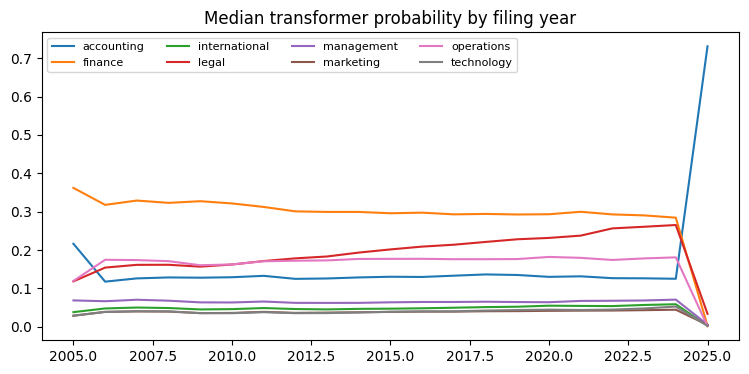

In [3]:
fig, ax = plt.subplots(figsize=(9,4))
r = risk[risk.words>0]
for f in FACTORS: ax.plot(r.groupby('file_year')[f+'_prob'].median(), label=f)
ax.set_title('Median transformer probability by filing year'); ax.legend(ncol=4, fontsize=8); plt.show()

## Marketing scores
The quarter is the call's calendar quarter (verified on IPO firms in DATA_AUDIT §3). The three constructs are nearly collinear.

In [4]:
print(mk[list(CONSTRUCTS)].corr().round(3)); pd.read_csv(T/'marketing_link_stats.csv', index_col=0)

            mkt_orient  mkt_capab  mkt_excel
mkt_orient       1.000      0.920      0.974
mkt_capab        0.920      1.000      0.894
mkt_excel        0.974      0.894      1.000


,value
rows_in,337599
rows_linked,195189
rows_ambiguous_dropped,5289
cik_quarters,189900


## Coverage funnel
How many filings per year reach the primary universe (current ticker, Yahoo prices, price ≥ $5, cap ≥ $100M, not a financial or utility).

In [5]:
pd.read_csv(T/'coverage_funnel.csv', index_col=0)

,filings,nonempty_item1a,current_sec_ticker,yahoo_prices,in_extended_universe,in_primary_universe,pct_primary_of_filings
file_year,,,,,,,
2005,5815,371,1515,1512,24,0,0.000
2006,5748,5469,1585,1581,894,0,0.000
2007,5741,5639,1664,1660,974,0,0.000
2008,6321,6088,1829,1825,973,0,0.000
2009,7917,7383,2154,2146,975,229,0.029
2010,7857,7388,2208,2199,1035,521,0.066
2011,7922,7516,2300,2291,1068,876,0.111
2012,7709,7374,2359,2351,1096,926,0.120
2013,7310,7047,2427,2418,1196,994,0.136
